In [3]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [366]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from matplotlib import gridspec
import seaborn as sns
import numpy as np
#from scipy.sparse import random
from scipy import stats
from numpy import linalg
from sklearn.decomposition import PCA
from torch.utils.data import TensorDataset, DataLoader
import random as rdm
#from Connectivity import *
plt.rcParams["axes.grid"] = False
import matplotlib
matplotlib.rcParams['axes.linewidth'] = .75


if torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'


class LDS(torch.nn.Module):
    def __init__(self, n, alpha=.2, input_size=2, output_size=50):
        super(LDS, self).__init__()
        self.alpha = torch.tensor(alpha)
        self.n = n
        self.observation_size = 50
        self.input_size = input_size
        self.output_size = output_size

       # self.activation = torch.nn.Softplus(beta = self.beta)
       #self.activation = torch.nn.ReLU()

        # Connectivity
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=False)
        self.input_layer = nn.Linear(self.input_size, self.n, bias=False)
        self.output_layer = nn.Linear(self.n, self.output_size, bias=False)



    # Dynamics
    def forward(self, u, training=False):
        t = u.shape[1]
        states = torch.zeros(u.shape[0], 1, self.n, device=device)

        inputs = self.input_layer(u)
        for i in range(t - 1):
            state_new = (1 - self.alpha) * states[:, i, :] + self.alpha * (
                self.recurrent_layer(states[:, i, :]) + inputs[:, i, :])
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        return states








<Axes: >

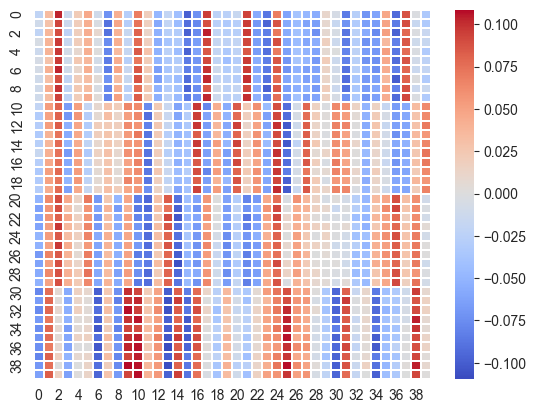

In [367]:
A = .1*np.concatenate([np.tile(2*np.random.rand(1,40)-1,[10,1]),
                    np.tile(2*np.random.rand(1,40)-1,[10,1]),
                    np.tile(2*np.random.rand(1,40)-1,[10,1]),
                    np.tile(2*np.random.rand(1,40)-1,[10,1])],axis=0)
A = A + .01*(2*np.random.rand(40,40)-1)
sns.heatmap(A,center=0,linewidths=.1,cmap="coolwarm")

<Axes: >

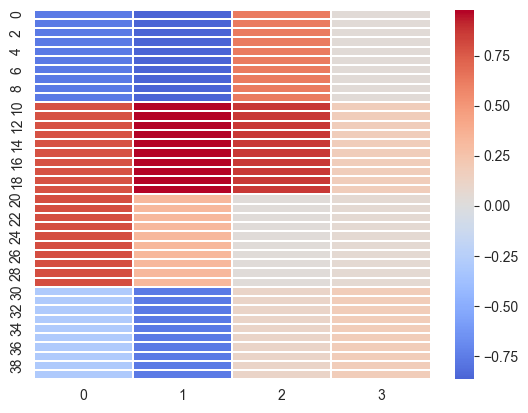

In [368]:
input_dim = 4
B = np.concatenate([np.tile(2*np.random.rand(1,input_dim)-1,[10,1]),
                    np.tile(2*np.random.rand(1,input_dim)-1,[10,1]),
                    np.tile(2*np.random.rand(1,input_dim)-1,[10,1]),
                    np.tile(2*np.random.rand(1,input_dim)-1,[10,1])],axis=0)
sns.heatmap(B,center=0,linewidths=.1,cmap="coolwarm")

<Axes: >

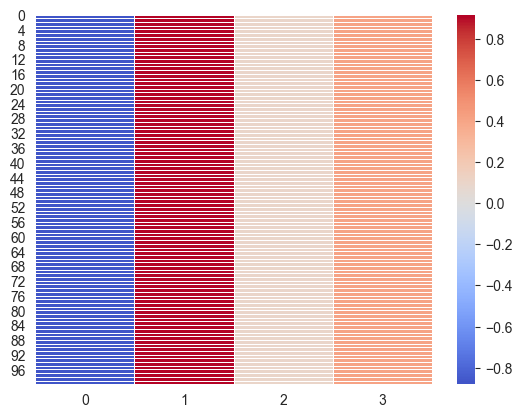

In [369]:
u = []
for trial in range(1000):
    u.append(np.tile(2*np.random.rand(input_dim,1)-1,[1,100]).T)
u = np.stack(u,axis=0)
plt.figure()
sns.heatmap(u[0,:,:],center=0,linewidths=.5,cmap="coolwarm")

In [370]:
u.shape

(1000, 100, 4)

In [426]:
a0 = np.zeros((40,40))
a1 = .4*np.random.rand(40,40)
skew_0 = (a0 - a0.T) / 2
skew_1 = (a1 - a1.T) / 2

skew = skew_0 + 0.5*(skew_1-skew_0)
eye = np.eye(40)
o = (eye - skew) @ np.linalg.inv(eye + skew)
#responses =  responses @ torch.tensor(o).float()

#responses = o @ responses

lds = LDS(n = 40,input_size = input_dim)
lds.recurrent_layer.weight.data = torch.tensor(o@A).float()
lds.input_layer.weight.data = torch.tensor(o@B).float()

In [427]:
y = lds(torch.tensor(u).float())

<Axes: >

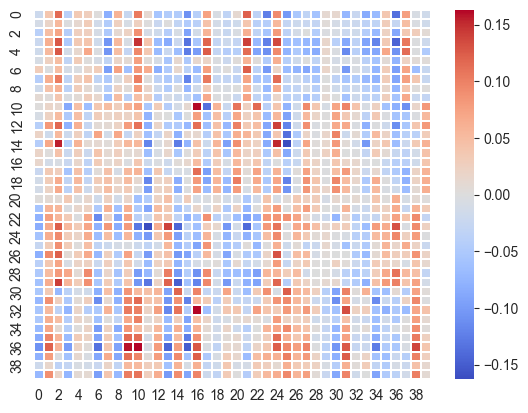

In [428]:
sns.heatmap(o@A,center=0,linewidths=.1,cmap="coolwarm")

<Axes: >

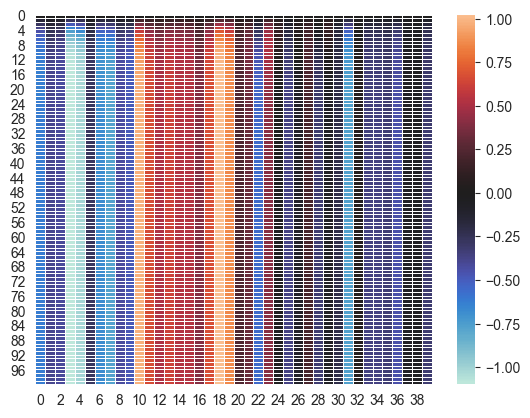

In [429]:
plt.figure()
sns.heatmap(y[1,:,:].detach(),center=0,lw=.5)

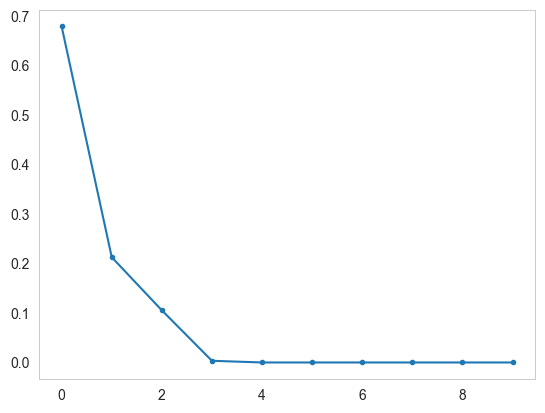

In [430]:
responses = y.detach().numpy().reshape(-1,y.shape[2])
pca = PCA().fit(responses)
plt.figure()
plt.plot(pca.explained_variance_ratio_[:10],marker='.')

In [431]:
x_proj = PCA().fit_transform(responses.T)

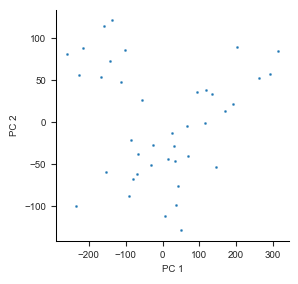

In [432]:
fig = plt.figure(figsize=(3,3))
gs = gridspec.GridSpec(1,1)


ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax,s=4)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
#ax.spines['bottom'].set_visible(False)
#ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)

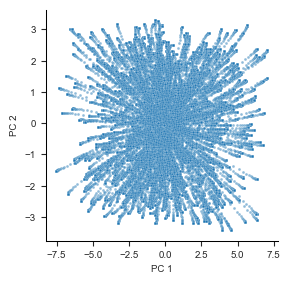

In [433]:
fig = plt.figure(figsize=(3,3))
gs = gridspec.GridSpec(1,1)

x_proj = PCA().fit_transform(responses)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax,s=4,alpha = .5)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
#ax.spines['bottom'].set_visible(False)
#ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)